In [1]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 4.2 MB/s eta 0:00:00


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Initializing Hybrid Pipeline (With Agnostic NMS & Confidence Filters)...


I0000 00:00:1789417385.695686      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789417385.698892      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



--- Processing Image 1/3 ---


2026-09-14 20:23:28.920942: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-14 20:23:29.060145: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-14 20:23:29.400220: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-14 20:23:29.539333: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1789417412.202599      79 device_compiler.h:196]

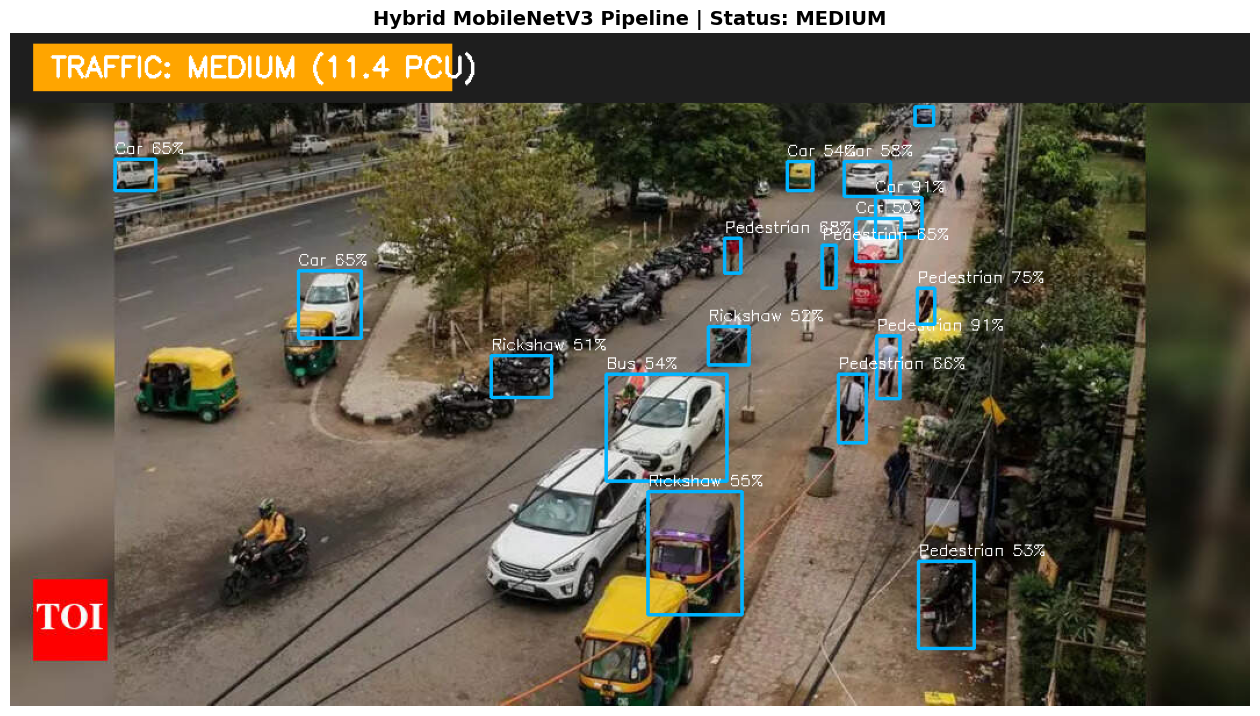


--- Processing Image 2/3 ---


2026-09-14 20:23:56.717946: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-14 20:23:56.853089: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-14 20:23:57.177384: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-14 20:23:57.315671: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


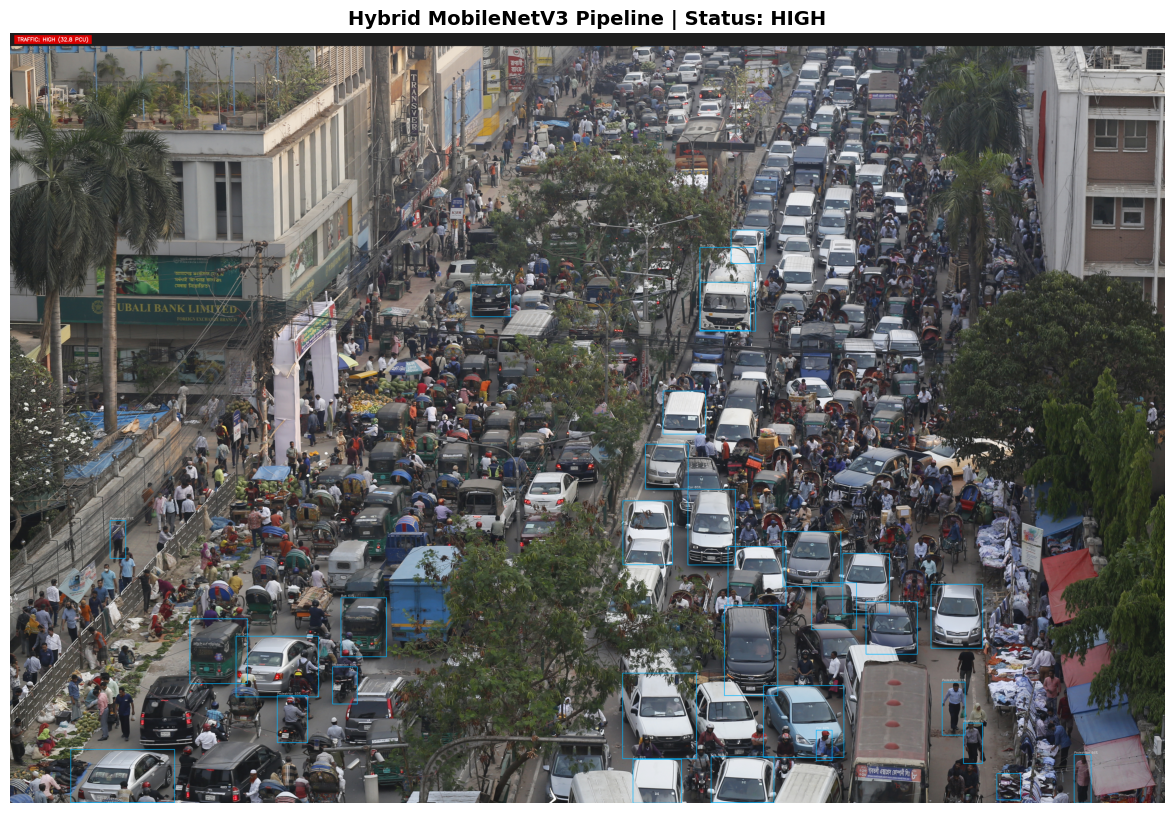


--- Processing Image 3/3 ---


2026-09-14 20:24:09.466701: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-14 20:24:09.599067: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-14 20:24:09.906571: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-14 20:24:10.042027: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


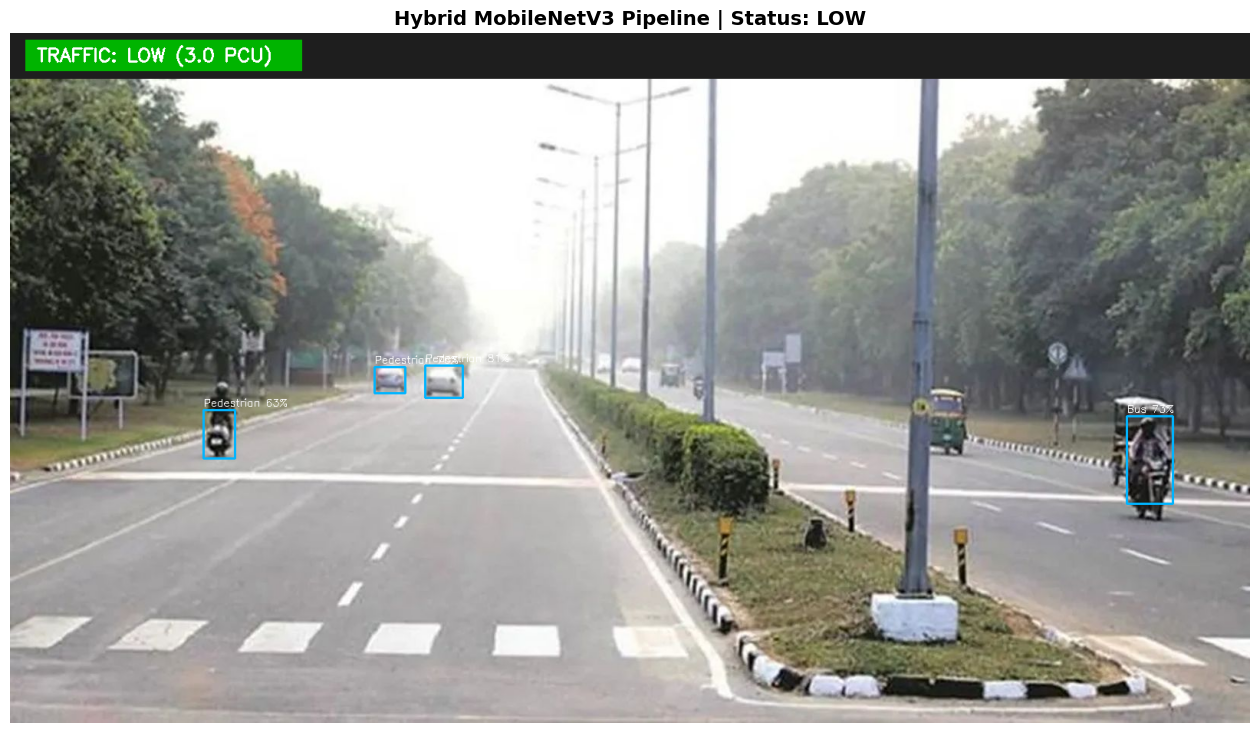

In [2]:
import os
import cv2
import requests
import numpy as np
import matplotlib.pyplot as plt
import torch
import tensorflow as tf
from tensorflow.keras.models import load_model
from ultralytics import YOLO

# 1. Clear GPU memory cache
if torch.cuda.is_available():
    torch.cuda.empty_cache()

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("Initializing Hybrid Pipeline (With Agnostic NMS & Confidence Filters)...")

# 2. Auto-Detect MobileNet Weights
MODEL_PATH = None
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if 'mobilenet' in file.lower() and file.endswith('.keras'):
            MODEL_PATH = os.path.join(root, file)
            break
    if MODEL_PATH:
        break

if not MODEL_PATH:
    raise FileNotFoundError("Could not find MobileNetV3 .keras weights.")

mobilenet_model = load_model(MODEL_PATH)
yolo_scout = YOLO('yolov8n.pt') 

# Alphabetical class mapping matching Keras flow_from_directory
CLASSES = sorted(["Car", "Bus", "Truck", "Motorcycle", "Bicycle", "Rickshaw", "Mini-Truck", "CNG", "Pedestrian"])

PCU_WEIGHTS = {
    'Car': 1.0, 'Bus': 3.0, 'Truck': 3.0, 'Mini-Truck': 1.5,
    'CNG': 0.75, 'Rickshaw': 0.8, 'Motorcycle': 0.4, 'Bicycle': 0.3, 'Pedestrian': 0.0
}
low_cutoff, high_cutoff = 8.45, 15.80

def hybrid_traffic_analyzer(image_path):
    img = cv2.imread(image_path)
    h, w, _ = img.shape
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    total_pcu = 0.0
    
    # 1. Scout Pass: agnostic_nms=True forces overlapping person/vehicle boxes to merge
    results = yolo_scout.predict(
        source=image_path, 
        conf=0.20, 
        imgsz=1024,
        classes=[0, 1, 2, 3, 5, 7], 
        agnostic_nms=True, 
        verbose=False
    )[0]
    
    crops = []
    coords = []
    
    for box in results.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w, x2), min(h, y2)
        
        if x2 - x1 < 12 or y2 - y1 < 12:
            continue
            
        crop = img_rgb[y1:y2, x1:x2]
        crop_resized = cv2.resize(crop, (224, 224)) / 255.0
        crops.append(crop_resized)
        coords.append((x1, y1, x2, y2))
        
    # 2. MobileNetV3 Classification Pass
    if crops:
        batch = tf.convert_to_tensor(crops, dtype=tf.float32)
        preds = mobilenet_model.predict(batch, verbose=0)
        
        for i, pred in enumerate(preds):
            confidence = np.max(pred)
            top_class_idx = np.argmax(pred)
            predicted_class = CLASSES[top_class_idx]
            
            # THE FIX: Drop hallucinations on blurry background objects
            if confidence < 0.50:
                continue
            
            total_pcu += PCU_WEIGHTS.get(predicted_class, 0.0)
            
            x1, y1, x2, y2 = coords[i]
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 180, 0), 2)
            
            # Display confidence percentage so you can audit the model's logic
            cv2.putText(img, f"{predicted_class} {confidence*100:.0f}%", (x1, max(15, y1 - 5)), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1)

    # 3. Congestion Classification
    if total_pcu < low_cutoff:
        status, banner_color = "LOW", (0, 180, 0)      
    elif total_pcu <= high_cutoff:
        status, banner_color = "MEDIUM", (0, 165, 255)    
    else:
        status, banner_color = "HIGH", (0, 0, 220)      

    # HUD Banner
    cv2.rectangle(img, (0, 0), (w, 60), (30, 30, 30), -1)
    cv2.rectangle(img, (20, 10), (380, 50), banner_color, -1)
    cv2.putText(img, f"TRAFFIC: {status} ({total_pcu:.1f} PCU)", (35, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)

    return img, status

# --- EXECUTION TEST ---
IMAGE_URLS = [
    "https://static.toiimg.com/thumb/msid-118190228,width-1070,height-580,imgsize-87732,resizemode-75,overlay-toi_sw,pt-32,y_pad-40/photo.jpg",
    "https://static.time.com/v3/assets/bltea6093859af6183b/bltd4c970056f6da5af/698a40c922fb856f5de2f1ba/Dhaka-traffic.jpg?branch=production", 
    "https://cf-img-a-in.tosshub.com/sites/visualstory/wp/2024/05/Chandigarh.webp?size=*:900"
]

headers = {'User-Agent': 'Mozilla/5.0'}

for i, url in enumerate(IMAGE_URLS):
    download_path = f"/kaggle/working/hybrid_test_RAW_{i+1}.jpg"
    output_path = f"/kaggle/working/hybrid_test_ANALYZED_{i+1}.jpg" 

    print(f"\n--- Processing Image {i+1}/3 ---")
    response = requests.get(url, headers=headers)
    
    if response.status_code == 200:
        with open(download_path, 'wb') as f:
            f.write(response.content)
            
        rendered_frame, level = hybrid_traffic_analyzer(download_path)
        cv2.imwrite(output_path, rendered_frame)
        
        plt.figure(figsize=(16, 10))
        plt.imshow(cv2.cvtColor(rendered_frame, cv2.COLOR_BGR2RGB))
        plt.axis('off')
        plt.title(f"Hybrid MobileNetV3 Pipeline | Status: {level}", fontsize=14, fontweight='bold')
        plt.show()